## Лабораторная работа 213

Ряд Фурье для периодического сигнала $f(t)$ с периодом $T$ ($\Omega = \frac{2\pi}{T}$):
$$ f(t) = \frac{a_0}{2} + \sum_{n=1}^{\infty} (a_n \cos n\Omega t + b_n \sin n\Omega t) $$
Коэффициенты ряда Фурье:
$$ a_n = \frac{2}{T} \int_{-T/2}^{T/2} f(t) \cos n\Omega t \, dt \quad (n = 0, 1, 2, \dots) \qquad  b_n = \frac{2}{T} \int_{-T/2}^{T/2} f(t) \sin n\Omega t \, dt \quad (n = 1, 2, \dots) $$

Амплитуда и фаза $n$-й гармоники:
$$ C_n = \sqrt{a_n^2 + b_n^2}, \qquad \varphi_n = \arctan \frac{a_n}{b_n} \qquad y_n = C_n \sin(\omega_n t + \varphi_n) $$

Комплексная форма ряда Фурье:
$$ f(t) = \sum_{n=-\infty}^{\infty} S_n e^{i n \Omega t}, \qquad S_n = \frac{1}{T} \int_{-T/2}^{T/2} f(t) e^{-i n \Omega t} \, dt, \qquad C_n = 2|S_n| $$

Интеграл Фурье для одиночного импульса ($T \to \infty$):
$$ f(t) = \frac{1}{2\pi} \int_{-\infty}^{\infty} \rho(\omega) e^{i \omega t} \, d\omega, \qquad \rho(\omega) = \int_{-\infty}^{\infty} f(t) e^{-i \omega t} \, dt $$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Часть 1

In [2]:
from dataclasses import dataclass, field

@dataclass(slots=True)
class Envelope: 
    x: np.ndarray = field(default_factory=lambda: np.empty(0))
    y: np.ndarray = field(default_factory=lambda: np.empty(0))

def plot_graph(harmonics: pd.DataFrame, envelope: Envelope, level_e: float | None = None) -> None:
    plt.figure(figsize=(16, 9))
    plt.stem(
        harmonics["freq, kHz"],
        harmonics["A, mV"],
        linefmt="b-",
        markerfmt="bo",
        basefmt=" ",
        # label="Измеренные гармоники (n = 1, 3, 5, 7, 9)",
    )
    plt.plot(
        envelope.x, envelope.y, "r--", linewidth=2, label=r"Огибающая $A(\nu) \propto 1/\nu$"
    )
    if level_e is not None:
        plt.axhline(
            level_e,
            color="g",
            linestyle=":",
            label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
        )

    plt.title("Спектр и огибающая прямоугольного сигнала (меандра)")
    plt.xlabel("Частота $\\nu$, кГц")
    plt.ylabel("Амплитуда $A$, мВ")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

##### Квадратный сигнал:

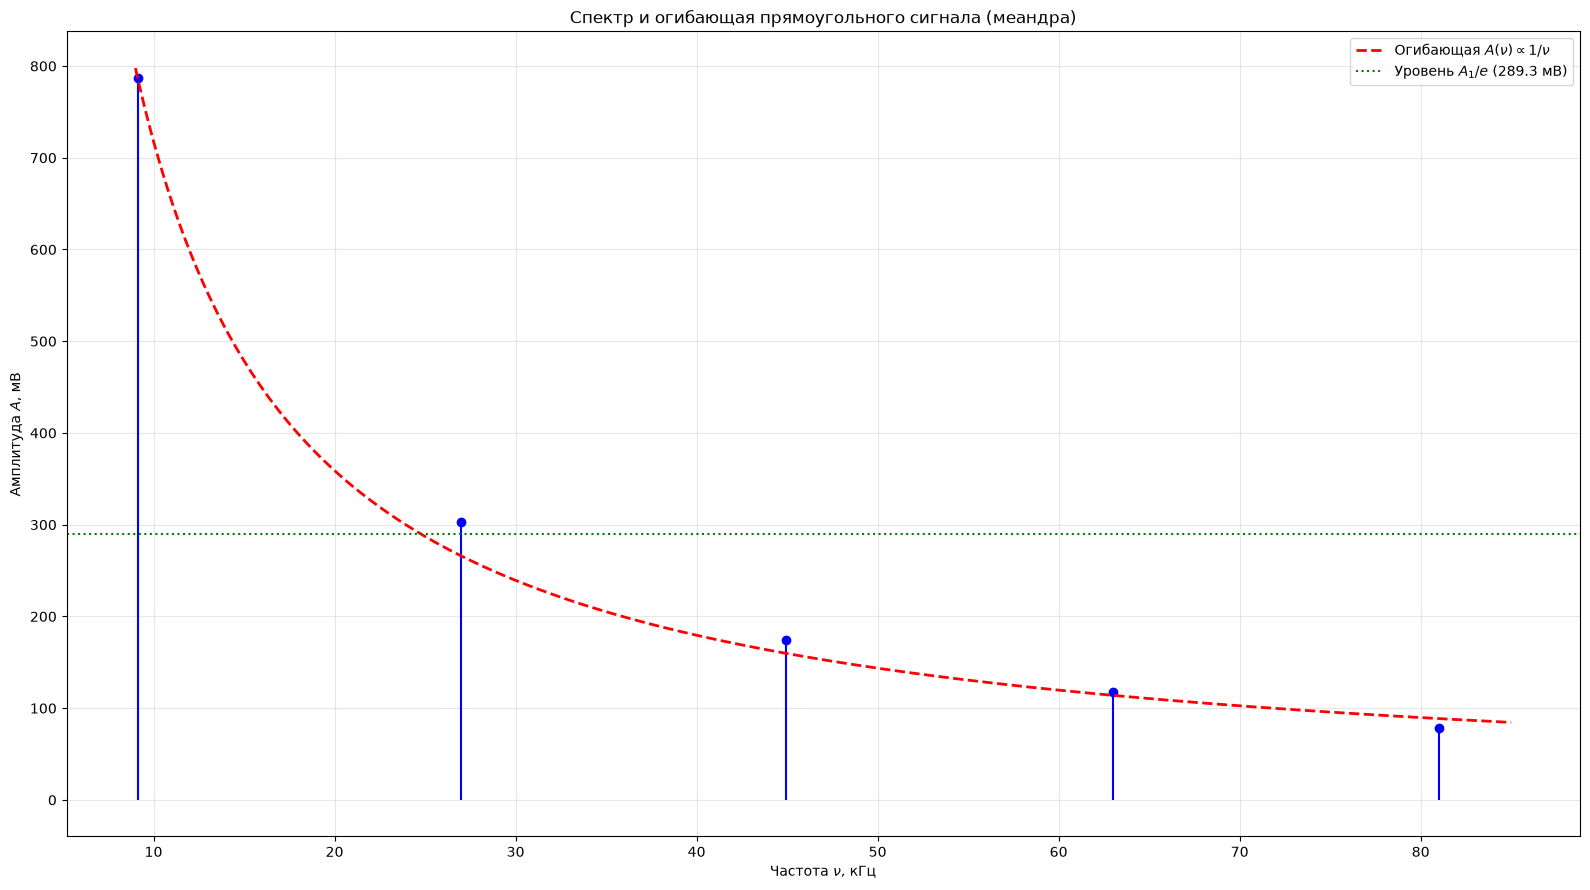

In [3]:
harmonics = pd.DataFrame({
    "freq, kHz": [9.129, 26.97, 44.96, 63.02, 81.01],
    "A, mV": [786.5, 302.5, 174.4, 117.4, 78.29],
    "n": [1, 3, 5, 7, 9],
}) # Гармоники
T = (107.7 - 1.854) * 1e-6  # период, с

# Теоретическая огибающая
f_grid = np.linspace(9, 85, 300)
f1 = harmonics["freq, kHz"].iloc[0]
A1 = harmonics["A, mV"].iloc[0]
envelope = A1 * f1 / f_grid

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e

plot_graph(harmonics, Envelope(f_grid, envelope), level_e)

#### Синусоида:

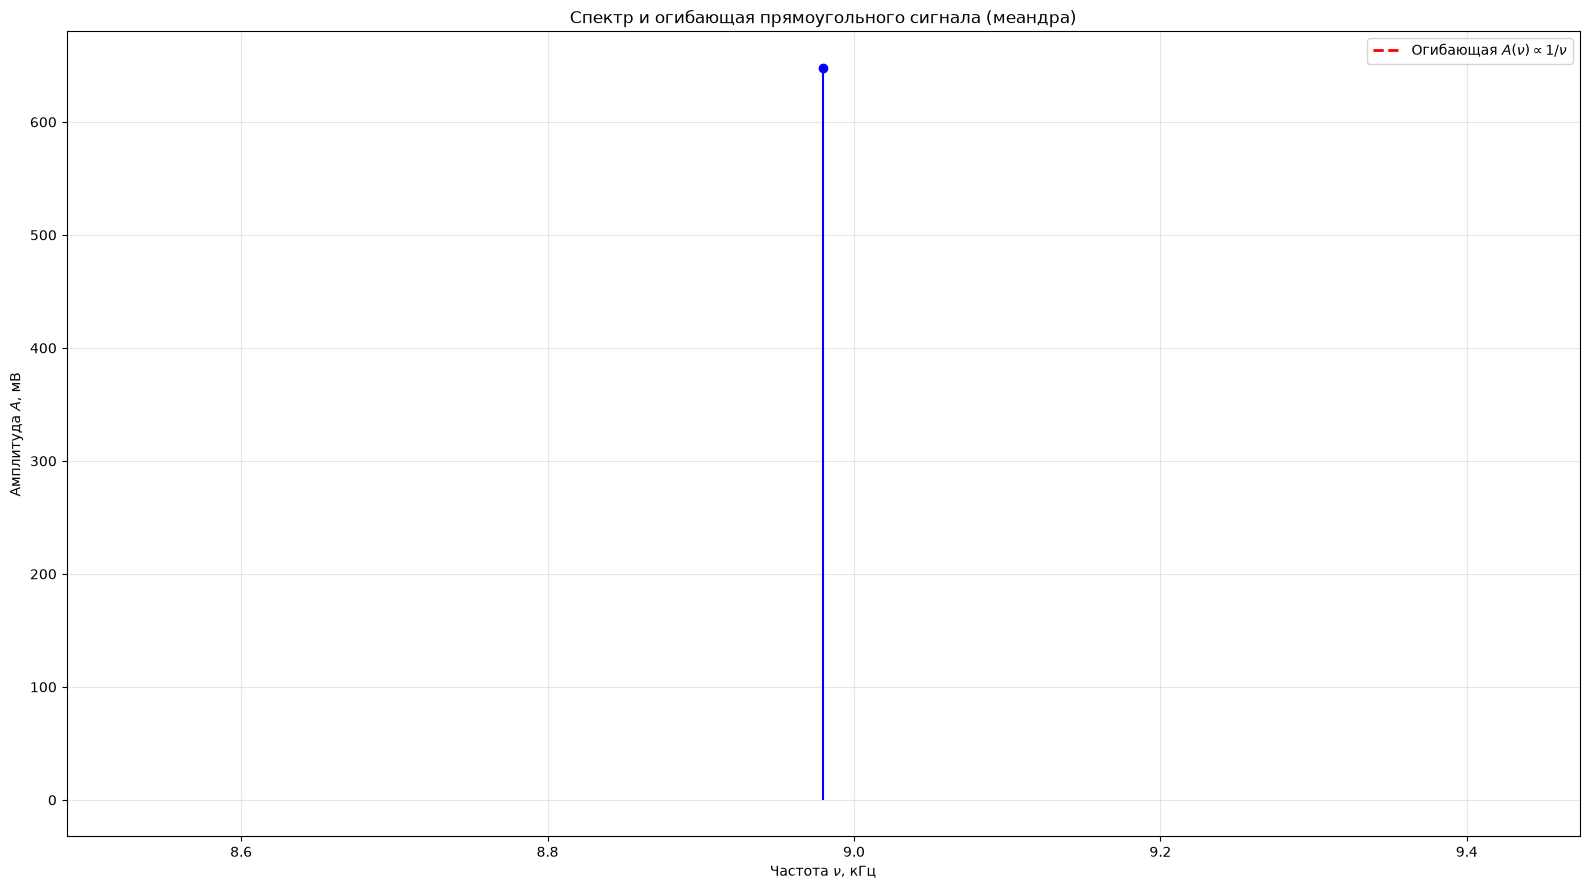

In [4]:
harmonics = pd.DataFrame({
    "freq, kHz": [8.98],
    "A, mV": [647.7],
})
T = (196 - 84.79) * 1e-6  # 111.21 мкс

plot_graph(harmonics, Envelope())

### Треугольный сигнал

Период T = 111.63 мкс, длительность на полувысоте tau = 55.81 мкс
Ширина спектра (по уровню 1/e): df = 14.81 кГц
Произведение неопределённостей df * tau = 0.83


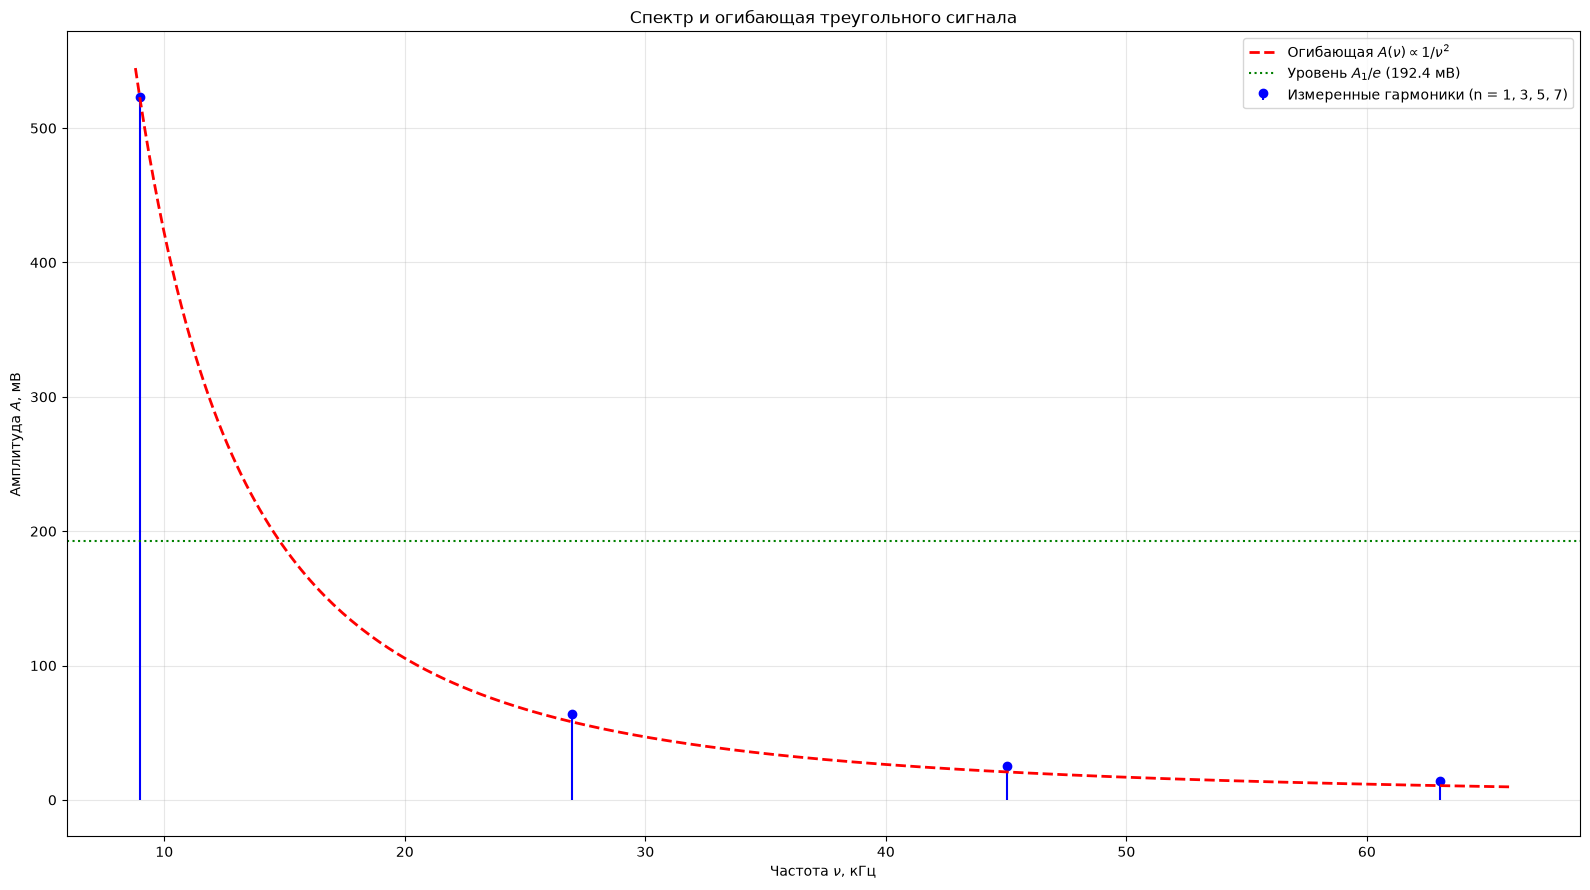

In [5]:
harmonics = pd.DataFrame({
    "freq, kHz": [8.98, 26.97, 45.03, 63.02],
    "A, mV": [523.1, 64.06, 24.91, 14.23],
})

T = (196.8 - 85.17) * 1e-6  # 111.63 мкс
tau = T / 2  # длительность импульса на полувысоте, с

# Добавлен индекс [0]
f_grid = np.linspace(8.8, 66, 300)
f1 = harmonics["freq, kHz"].iloc[0]
A1 = harmonics["A, mV"].iloc[0]
envelope = A1 * (f1 / f_grid) ** 2

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e
df_exp = f1 * np.sqrt(np.e)

print(
    f"Период T = {T*1e6:.2f} мкс, длительность на полувысоте tau = {tau*1e6:.2f}"
    " мкс"
)
print(f"Ширина спектра (по уровню 1/e): df = {df_exp:.2f} кГц")
print(f"Произведение неопределённостей df * tau = {(df_exp * 1e3) * tau:.2f}")

# График
plt.figure(figsize=(16, 9))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1, 3, 5, 7)",
)
plt.plot(
    f_grid,
    envelope,
    "r--",
    linewidth=2,
    label=r"Огибающая $A(\nu) \propto 1/\nu^2$",
)
plt.axhline(
    level_e,
    color="g",
    linestyle=":",
    label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
)

plt.title("Спектр и огибающая треугольного сигнала")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Пилообразный сигнал (повышающийся)

Период T = 112.79 мкс, длительность на полувысоте tau = 56.39 мкс
Ширина спектра (по уровню 1/e): df = 24.21 кГц
Произведение неопределённостей df * tau = 1.37


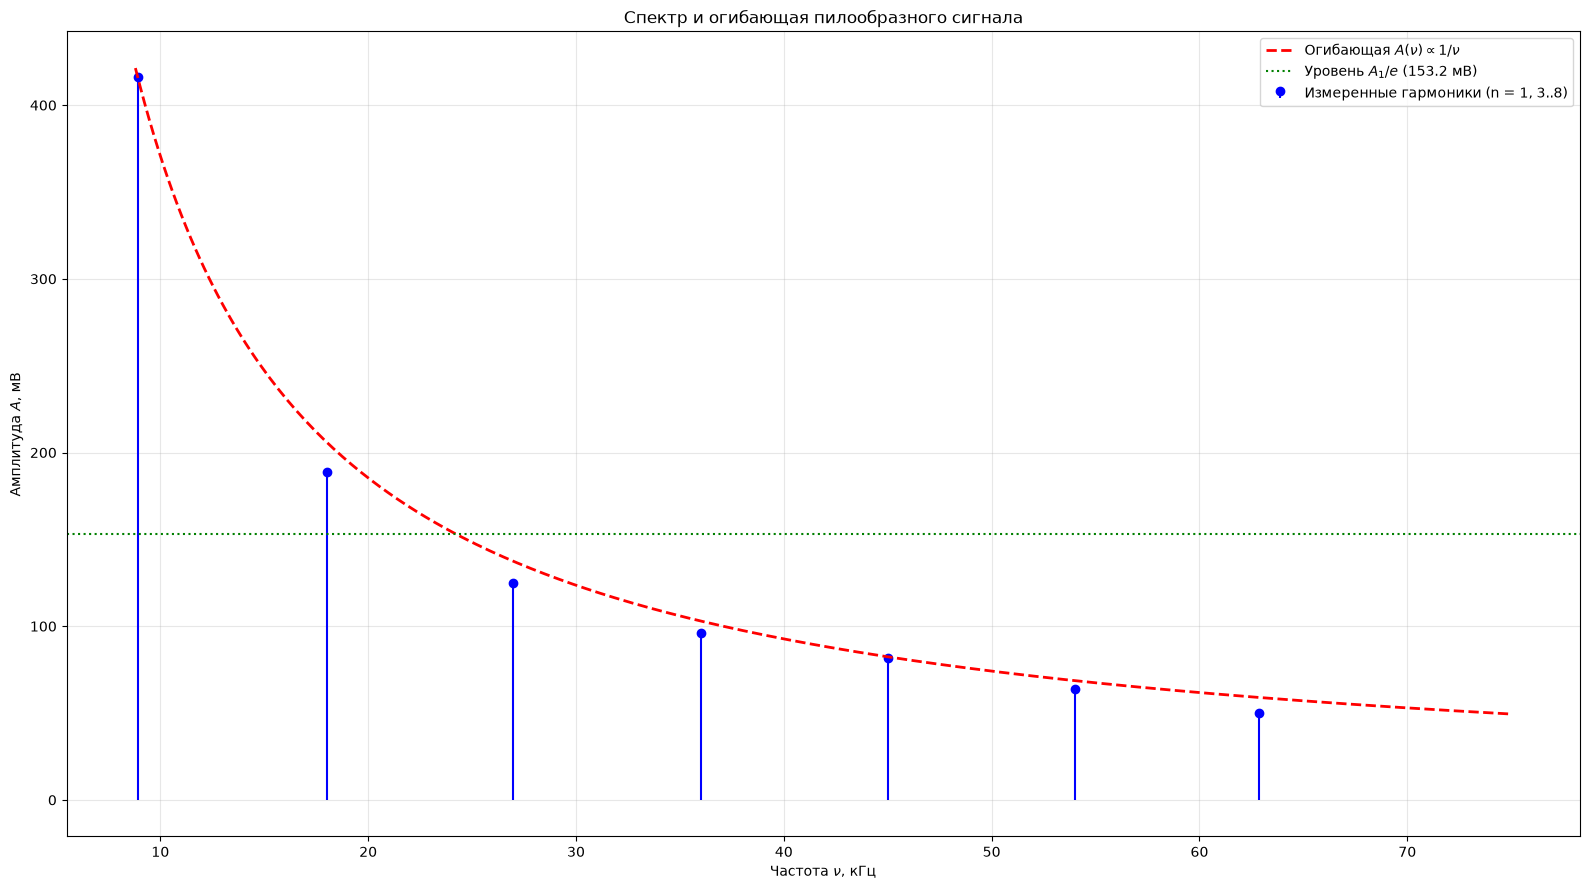

In [6]:
harmonics = pd.DataFrame({
    "freq, kHz": [8.905, 18.01, 26.97, 36.0, 45.03, 53.99, 62.87],
    "A, mV":     [416.4, 188.6, 124.6, 96.09, 81.85, 64.06, 49.82],
    "n": [1, 3, 4, 5, 6, 7, 8],
})

T = (173.5 - 60.71) * 1e-6  # 112.79 мкс
tau = T / 2  # длительность импульса на полувысоте, с

f1 = float(np.asarray(harmonics["freq, kHz"])[0])
A1 = float(np.asarray(harmonics["A, mV"])[0])

f_grid = np.linspace(8.8, 75, 300)
envelope = A1 * f1 / f_grid

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e
df_exp = f1 * np.e

print(
    f"Период T = {T*1e6:.2f} мкс, длительность на полувысоте tau = {tau*1e6:.2f}"
    " мкс"
)
print(f"Ширина спектра (по уровню 1/e): df = {df_exp:.2f} кГц")
print(f"Произведение неопределённостей df * tau = {(df_exp * 1e3) * tau:.2f}")

# Построение графика
plt.figure(figsize=(16, 9))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1, 3..8)",
)
plt.plot(
    f_grid, envelope, "r--", linewidth=2, label=r"Огибающая $A(\nu) \propto 1/\nu$"
)
plt.axhline(
    level_e,
    color="g",
    linestyle=":",
    label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
)

plt.title("Спектр и огибающая пилообразного сигнала")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Пилообразный сигнал (понижающийся)

Период T = 107.40 мкс, длительность на полувысоте tau = 53.70 мкс
Ширина спектра (по уровню 1/e): df = 24.21 кГц
Произведение неопределённостей df * tau = 1.30


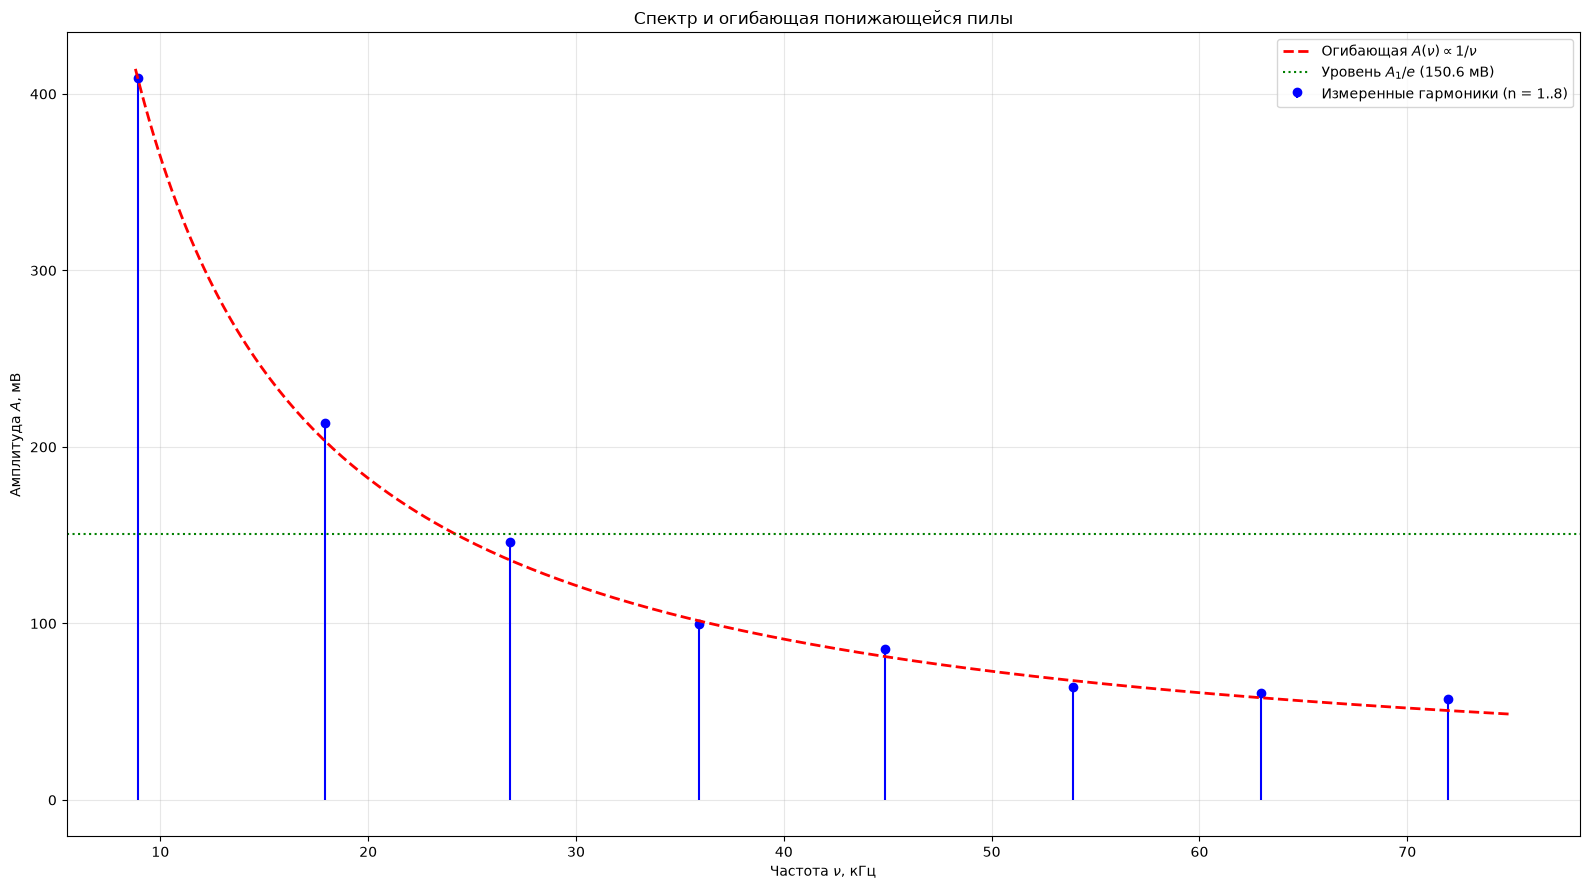

In [7]:
harmonics = pd.DataFrame({
    "freq, kHz": [8.905, 17.94, 26.82, 35.93, 44.88, 53.92, 62.95, 71.98],
    "A, mV": [409.3, 213.5, 145.9, 99.64, 85.41, 64.06, 60.5, 56.94],
    "n": list(range(1, 9)),
})

T = (219.7 - 112.3) * 1e-6  # 107.4 мкс
tau = T / 2  # длительность импульса на полувысоте, с

f1 = float(np.asarray(harmonics["freq, kHz"]).item(0))
A1 = float(np.asarray(harmonics["A, mV"]).item(0))

# Теоретическая огибающая A(f) = A1 * f1 / f
f_grid = np.linspace(8.8, 75, 300)
envelope = A1 * f1 / f_grid

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e
df_exp = f1 * np.e

print(
    f"Период T = {T*1e6:.2f} мкс, длительность на полувысоте tau = {tau*1e6:.2f}"
    " мкс"
)
print(f"Ширина спектра (по уровню 1/e): df = {df_exp:.2f} кГц")
print(f"Произведение неопределённостей df * tau = {(df_exp * 1e3) * tau:.2f}")

# Построение графика
plt.figure(figsize=(16, 9))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1..8)",
)
plt.plot(
    f_grid, envelope, "r--", linewidth=2, label=r"Огибающая $A(\nu) \propto 1/\nu$"
)
plt.axhline(
    level_e,
    color="g",
    linestyle=":",
    label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
)

plt.title("Спектр и огибающая понижающейся пилы")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Гаусс:

Период T = 110.47 мкс
Ширина спектра по уровню 1/e (из аппроксимации): df = 16.59 кГц
Оценка полуширины импульса tau = 19.19 мкс
Произведение неопределённостей df * tau = 0.32


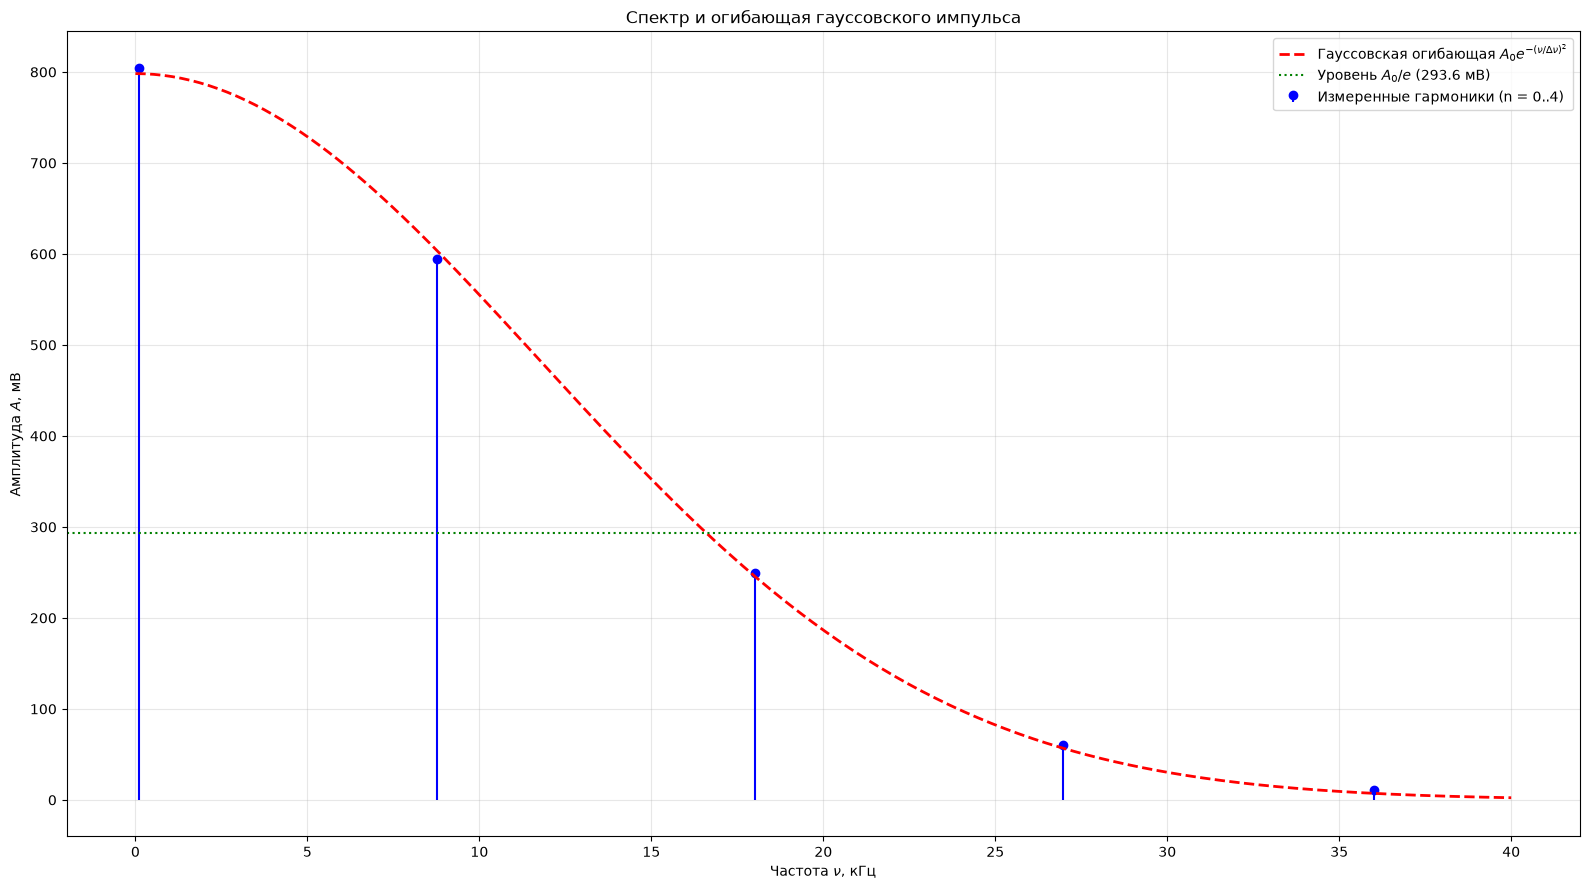

Измеренная длительность на полувысоте tau_0.5 = 81.47 мкс
Ширина спектра на полувысоте df_0.5 = 13.81 кГц
Экспериментальное произведение неопределённостей df_0.5 * tau_0.5 = 1.13 (теория ~ 0.44)


In [8]:
from scipy.optimize import curve_fit

harmonics = pd.DataFrame({
    "freq, kHz": [0.097, 8.756, 18.01, 26.97, 36.0],
    "A, mV": [804.3, 594.3, 249.1, 60.5, 10.68],
    "n": list(range(5)),  # 0, 1, 2, 3, 4
})

T = (207.1 - 96.63) * 1e-6  # 110.47 мкс


# Аппроксимация огибающей гауссовской кривой A(f) = A0 * exp(-(f / df)^2)
def gauss_env(f, A0, df):
  return A0 * np.exp(-((f / df) ** 2))


popt, _ = curve_fit(
    gauss_env, harmonics["freq, kHz"], harmonics["A, mV"], p0=(804.3, 16.0)
)
A0_fit, df_fit = popt

f_grid = np.linspace(0, 40, 300)
envelope = gauss_env(f_grid, A0_fit, df_fit)

# Оценка длительности импульса по соотношению неопределённостей
# Для гауссовского импульса exp(-(t/tau)^2) и спектра exp(-(w*tau/2)^2): df * tau = 1 / pi
tau_est = 1 / (np.pi * df_fit * 1e3)
level_e = A0_fit / np.e

print(f"Период T = {T*1e6:.2f} мкс")
print(
    f"Ширина спектра по уровню 1/e (из аппроксимации): df = {df_fit:.2f} кГц"
)
print(f"Оценка полуширины импульса tau = {tau_est*1e6:.2f} мкс")
print(
    f"Произведение неопределённостей df * tau = {(df_fit * 1e3) * tau_est:.2f}"
)

# График
plt.figure(figsize=(16, 9))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 0..4)",
)
plt.plot(
    f_grid,
    envelope,
    "r--",
    linewidth=2,
    label=r"Гауссовская огибающая $A_0 e^{-(\nu/\Delta\nu)^2}$",
)
plt.axhline(
    level_e,
    color="g",
    linestyle=":",
    label=f"Уровень $A_0/e$ ({level_e:.1f} мВ)",
)

plt.title("Спектр и огибающая гауссовского импульса")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
# Подставьте ваши измеренные времена (в мкс) на уровне половины пика:
t1 = -192.6  # левый фронт на 0.5 от пика, мкс
t2 = -111.13  # правый фронт на 0.5 от пика, мкс
tau_half = (t2 - t1) * 1e-6  # длительность на полувысоте, с

# Ширина спектра на полувысоте (0.5 от A0) из вашей аппроксимации (df_fit = 16.0 кГц):
df_half = df_fit * np.sqrt(np.log(2))  # ~ 13.3 кГц

print(f"Измеренная длительность на полувысоте tau_0.5 = {tau_half*1e6:.2f} мкс")
print(f"Ширина спектра на полувысоте df_0.5 = {df_half:.2f} кГц")
print(
    "Экспериментальное произведение неопределённостей df_0.5 * tau_0.5 ="
    f" {(df_half * 1e3) * tau_half:.2f} (теория ~ 0.44)"
)


### Часть 2

#### Прямоугольный сигнал. Скважность 4

Таблица сравнения относительных амплитуд (T/tau = 4, без 0-й гармоники):
 n  freq, kHz  (Cn/C1)_эксп  (Cn/C1)_теор
 1      18.09         1.000         1.000
 2      36.08         0.645         0.707
 3      54.06         0.318         0.333
 4      69.22         0.122         0.000

Ширина главного лепестка спектра: df = 72.36 кГц (по эксперименту 4-я гармоника на 69.22 кГц)
Произведение неопределённостей df * tau (номинальное) = 1.01
Произведение неопределённостей df * tau (измеренное 9.2 мкс) = 0.67


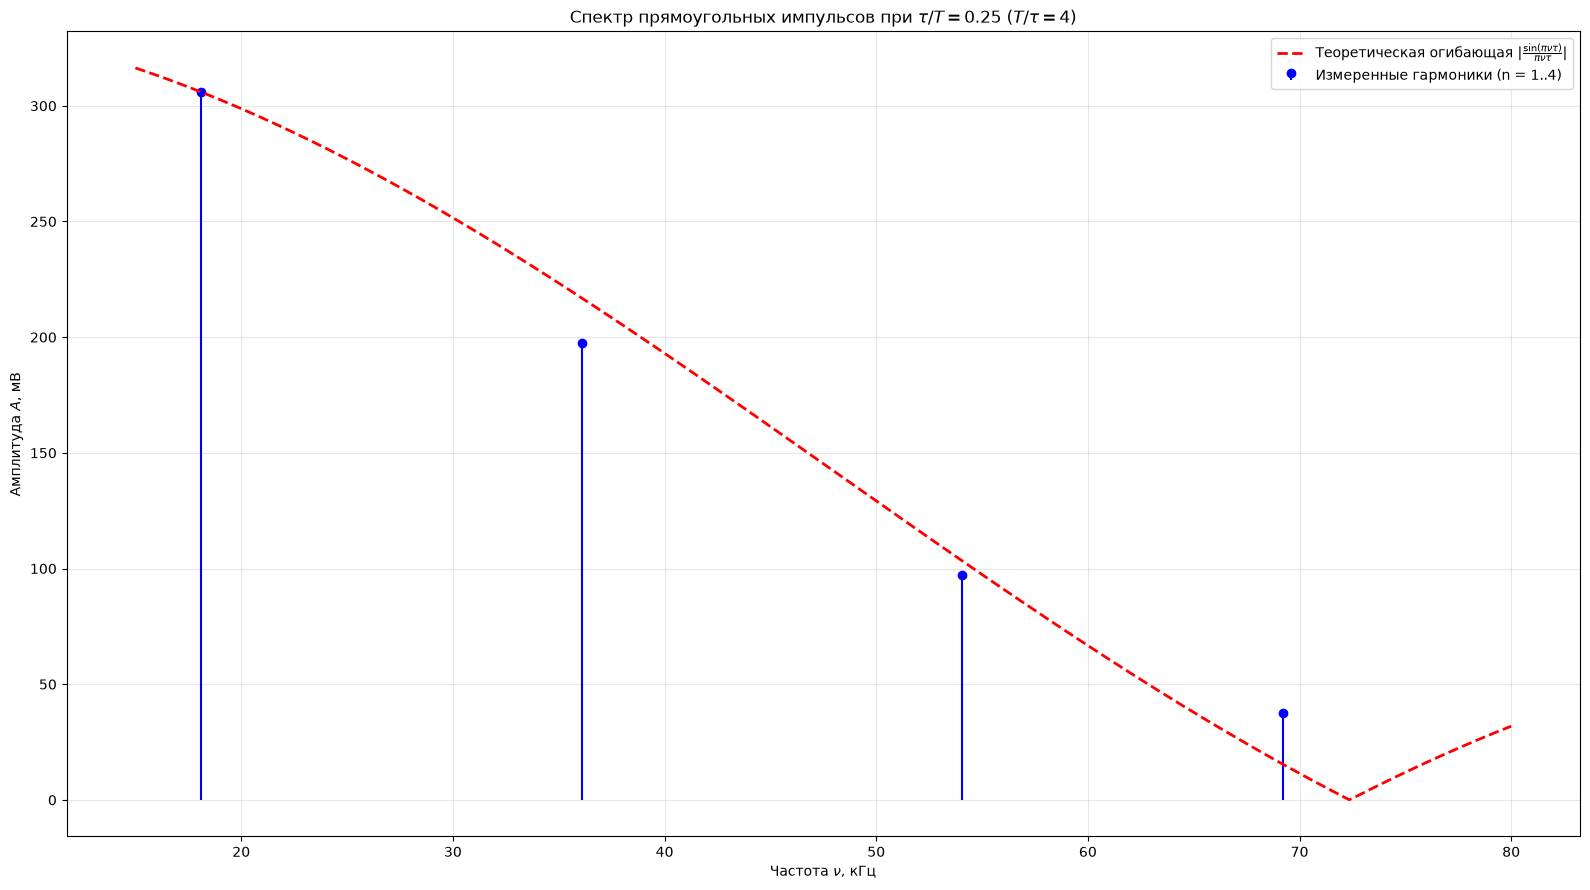

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

harmonics = pd.DataFrame({
    "freq, kHz": (18.09, 36.08, 54.06, 69.22),
    "A, mV": (306.0, 197.5, 97.36, 37.37),
    "n": (1, 2, 3, 4),
})

T = (210.1 - 154.3) * 1e-6  # 55.8 мкс
tau = (163.5 - 154.3) * 1e-6  # 9.2 мкс
duty = 0.25  # заданный коэффициент заполнения tau / T = 1/4

f1 = float(np.asarray(harmonics["freq, kHz"]).item(0))  # 18.09 кГц
A1 = float(np.asarray(harmonics["A, mV"]).item(0))  # 306.0 мВ

# Амплитуда огибающей в нуле (восстановлена по 1-й гармонике)
A_env0 = A1 * (np.pi * duty) / np.sin(np.pi * duty)

# Теоретическая огибающая |sin(pi * f * tau) / (pi * f * tau)| при tau = 0.25 * T
f_grid = np.linspace(15, 80, 400)
x = np.pi * (f_grid / f1) * duty
envelope = A_env0 * np.abs(np.sin(x) / x)

# Таблица сравнения относительных амплитуд (n = 1..4)
n_arr = np.asarray(harmonics["n"])
rel_exp = np.asarray(harmonics["A, mV"]) / A1
rel_theor = (1 / n_arr) * np.abs(
    np.sin(np.pi * n_arr * duty) / np.sin(np.pi * duty)
)

df_compare = pd.DataFrame({
    "n": n_arr,
    "freq, kHz": harmonics["freq, kHz"],
    "(Cn/C1)_эксп": np.round(rel_exp, 3),
    "(Cn/C1)_теор": np.round(rel_theor, 3),
})
print("Таблица сравнения относительных амплитуд (T/tau = 4, без 0-й гармоники):")
print(df_compare.to_string(index=False))

# Оценка ширины спектра (до первого нуля огибающей f_zero = 4 * f1)
df_spec = 4 * f1  # ~ 72.36 кГц
tau_nom = duty * T  # номинальная длительность 0.25 * T = 13.95 мкс
print(
    f"\nШирина главного лепестка спектра: df = {df_spec:.2f} кГц (по"
    " эксперименту 4-я гармоника на 69.22 кГц)"
)
print(
    "Произведение неопределённостей df * tau (номинальное) ="
    f" {(df_spec * 1e3) * tau_nom:.2f}"
)
print(
    "Произведение неопределённостей df * tau (измеренное 9.2 мкс) ="
    f" {(df_spec * 1e3) * tau:.2f}"
)

# Построение графика
plt.figure(figsize=(16, 9))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1..4)",
)
plt.plot(
    f_grid,
    envelope,
    "r--",
    linewidth=2,
    label=r"Теоретическая огибающая $|\frac{\sin(\pi \nu \tau)}{\pi \nu \tau}|$",
)

plt.title(r"Спектр прямоугольных импульсов при $\tau/T = 0.25$ ($T/\tau = 4$)")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


#### Прямоугольные импульсы. Скважность 2

Таблица сравнения относительных амплитуд (T/tau = 2):
 n  freq, kHz  (Cn/C1)_эксп  (Cn/C1)_теор
 1      17.94         1.000         1.000
 3      53.92         0.319         0.333
 4      69.29         0.133         0.000
 5      90.04         0.195         0.200

Ширина главного лепестка спектра (до первого нуля 2*f1): df = 35.88 кГц
Произведение неопределённостей df * tau (номинальное) = 0.98
Произведение неопределённостей df * tau (измеренное 23.0 мкс) = 0.83


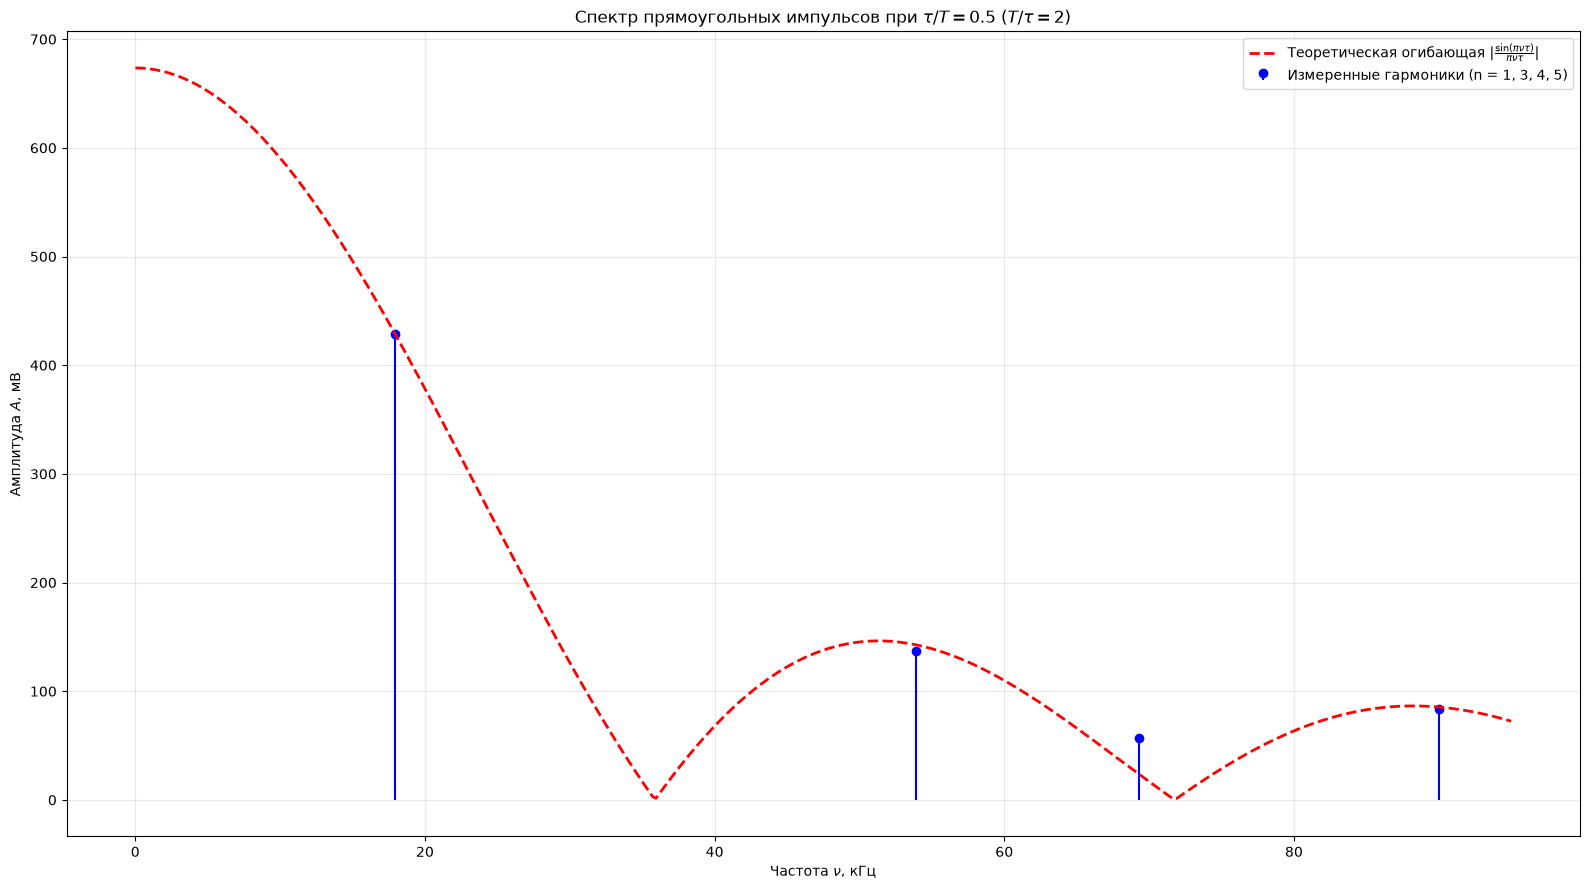

In [10]:
harmonics = pd.DataFrame({
    "freq, kHz": [17.94, 53.92, 69.29, 90.04],
    "A, mV": [428.8, 137.0, 56.94, 83.63],
    "n": (1, 3, 4, 5)
})

T = (219.3 - 164.7) * 1e-6  # 54.6 мкс
tau = (164.7 - 141.7) * 1e-6  # 23.0 мкс
duty = 0.5  # заданный коэффициент заполнения tau / T = 1/2

f1 = float(np.asarray(harmonics["freq, kHz"]).item(0))  # 17.94 кГц
A1 = float(np.asarray(harmonics["A, mV"]).item(0))  # 428.8 мВ

# Амплитуда огибающей в нуле
A_env0 = A1 * (np.pi * duty) / np.sin(np.pi * duty)

# Теоретическая огибающая |sin(pi * f * tau) / (pi * f * tau)| при tau = 0.5 * T
f_grid = np.linspace(0.01, 95, 400)
x = np.pi * (f_grid / f1) * duty
envelope = A_env0 * np.abs(np.sin(x) / x)

# Таблица сравнения относительных амплитуд (n = 1, 3, 4, 5)
n_arr = np.asarray(harmonics["n"])
rel_exp = np.asarray(harmonics["A, mV"]) / A1
rel_theor = (1 / n_arr) * np.abs(
    np.sin(np.pi * n_arr * duty) / np.sin(np.pi * duty)
)

df_compare = pd.DataFrame({
    "n": n_arr,
    "freq, kHz": harmonics["freq, kHz"],
    "(Cn/C1)_эксп": np.round(rel_exp, 3),
    "(Cn/C1)_теор": np.round(rel_theor, 3),
})
print("Таблица сравнения относительных амплитуд (T/tau = 2):")
print(df_compare.to_string(index=False))

# Оценка ширины спектра (до первого нуля огибающей f_zero = 2 * f1)
df_spec = 2 * f1  # ~ 35.88 кГц (первый нуль на месте 2-й гармоники)
tau_nom = duty * T  # номинальная длительность 0.5 * T = 27.3 мкс
print(
    f"\nШирина главного лепестка спектра (до первого нуля 2*f1): df = {df_spec:.2f}"
    " кГц"
)
print(
    "Произведение неопределённостей df * tau (номинальное) ="
    f" {(df_spec * 1e3) * tau_nom:.2f}"
)
print(
    "Произведение неопределённостей df * tau (измеренное 23.0 мкс) ="
    f" {(df_spec * 1e3) * tau:.2f}"
)

# Построение графика
plt.figure(figsize=(16, 9))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1, 3, 4, 5)",
)
plt.plot(
    f_grid,
    envelope,
    "r--",
    linewidth=2,
    label=r"Теоретическая огибающая $|\frac{\sin(\pi \nu \tau)}{\pi \nu \tau}|$",
)

plt.title(r"Спектр прямоугольных импульсов при $\tau/T = 0.5$ ($T/\tau = 2$)")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


#### Прямоугольный сигнал. Cкважность 4/3

Таблица сравнения относительных амплитуд (без 0-й гармоники):
 n  freq, kHz  (Cn/C1)_эксп  (Cn/C1)_теор
 1      18.01         1.000         1.000
 2      36.00         0.636         0.707
 3      53.99         0.289         0.333
 4      69.44         0.121         0.000
 5      90.04         0.202         0.200


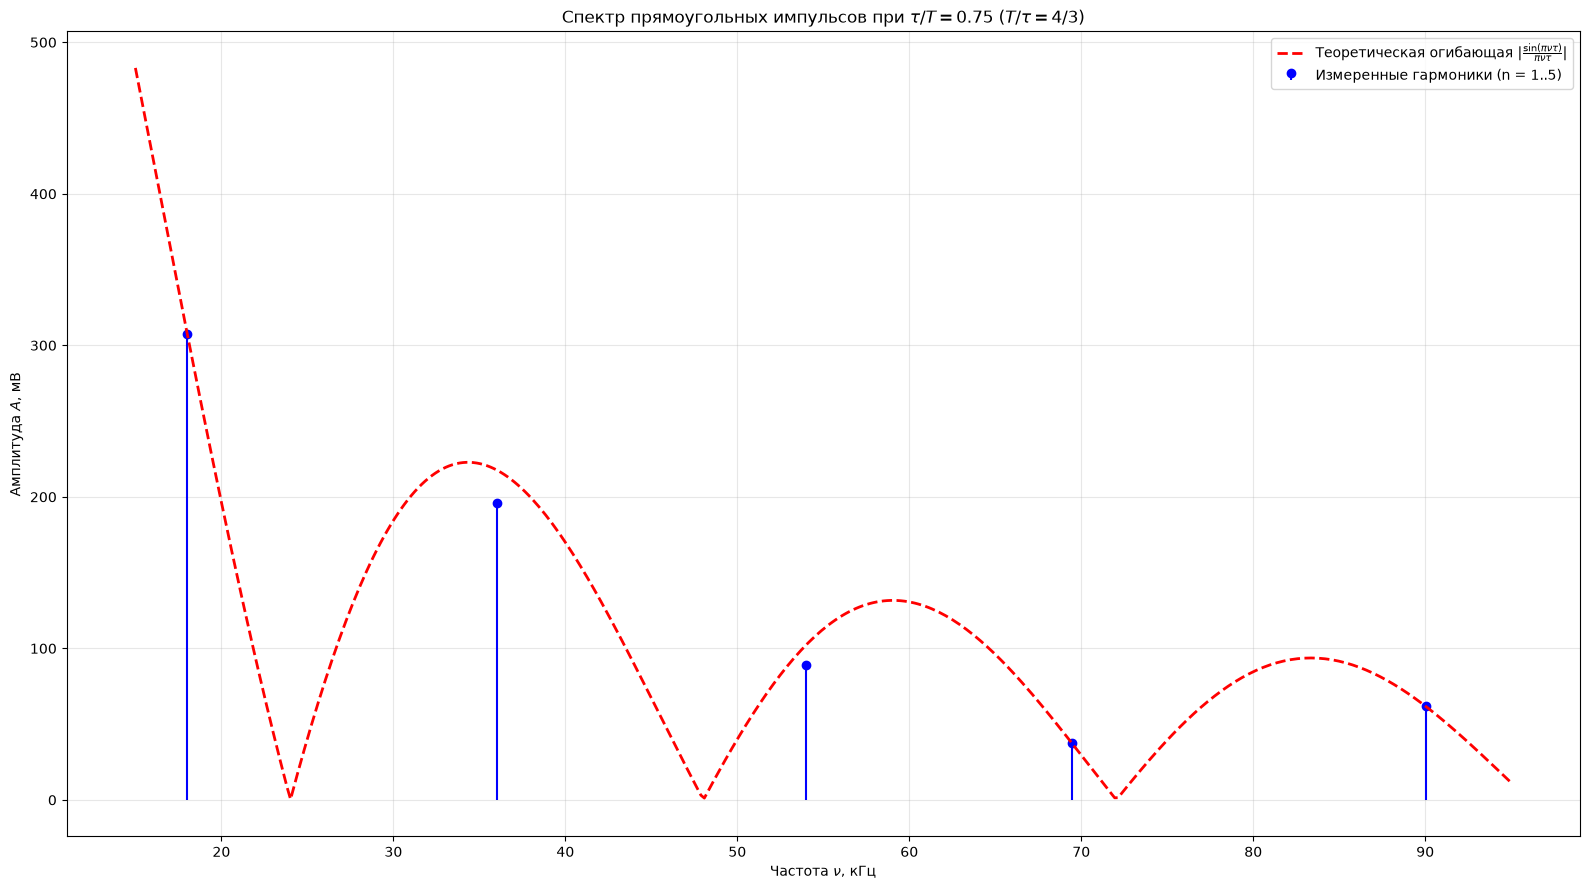

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

harmonics = pd.DataFrame({
    "freq, kHz": (18.01, 36.0, 53.99, 69.44, 90.04),
    "A, mV": (307.8, 195.7, 88.97, 37.37, 62.28),
    "n": (1, 2, 3, 4, 5),
})

T = (219.3 - 163.5) * 1e-6  # 55.8 мкс
duty = 0.75  # заданный коэффициент заполнения tau / T = 3/4

f1 = float(np.asarray(harmonics["freq, kHz"]).item(0))  # 18.01 кГц
A1 = float(np.asarray(harmonics["A, mV"]).item(0))  # 307.8 мВ

# Амплитуда огибающей в нуле (восстановлена по 1-й гармонике)
A_env0 = A1 * (np.pi * duty) / np.abs(np.sin(np.pi * duty))

# Теоретическая огибающая |sin(pi * f * tau) / (pi * f * tau)|
f_grid = np.linspace(15, 95, 400)
x = np.pi * (f_grid / f1) * duty
envelope = A_env0 * np.abs(np.sin(x) / x)

# Таблица сравнения относительных амплитуд (n = 1..5)
n_arr = np.asarray(harmonics["n"])
rel_exp = np.asarray(harmonics["A, mV"]) / A1
rel_theor = (1 / n_arr) * np.abs(
    np.sin(np.pi * n_arr * duty) / np.sin(np.pi * duty)
)

df_compare = pd.DataFrame({
    "n": n_arr,
    "freq, kHz": harmonics["freq, kHz"],
    "(Cn/C1)_эксп": np.round(rel_exp, 3),
    "(Cn/C1)_теор": np.round(rel_theor, 3),
})
print("Таблица сравнения относительных амплитуд (без 0-й гармоники):")
print(df_compare.to_string(index=False))

# Построение графика
plt.figure(figsize=(16, 9))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1..5)",
)
plt.plot(
    f_grid,
    envelope,
    "r--",
    linewidth=2,
    label=r"Теоретическая огибающая $|\frac{\sin(\pi \nu \tau)}{\pi \nu \tau}|$",
)

plt.title(
    r"Спектр прямоугольных импульсов при $\tau/T = 0.75$ ($T/\tau = 4/3$)"
)
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Часть 3

#### Прямоугольный сигнал. Скважность 2 и 4


=== Скважность T/tau = 2 (меандр) ===
    Цепочка  f_ср эксп, кГц  f_ср теор, кГц
C1 = 100 пФ            99.5           159.2
C2 = 200 пФ            60.7            79.6
C3 = 530 пФ            24.0            30.0


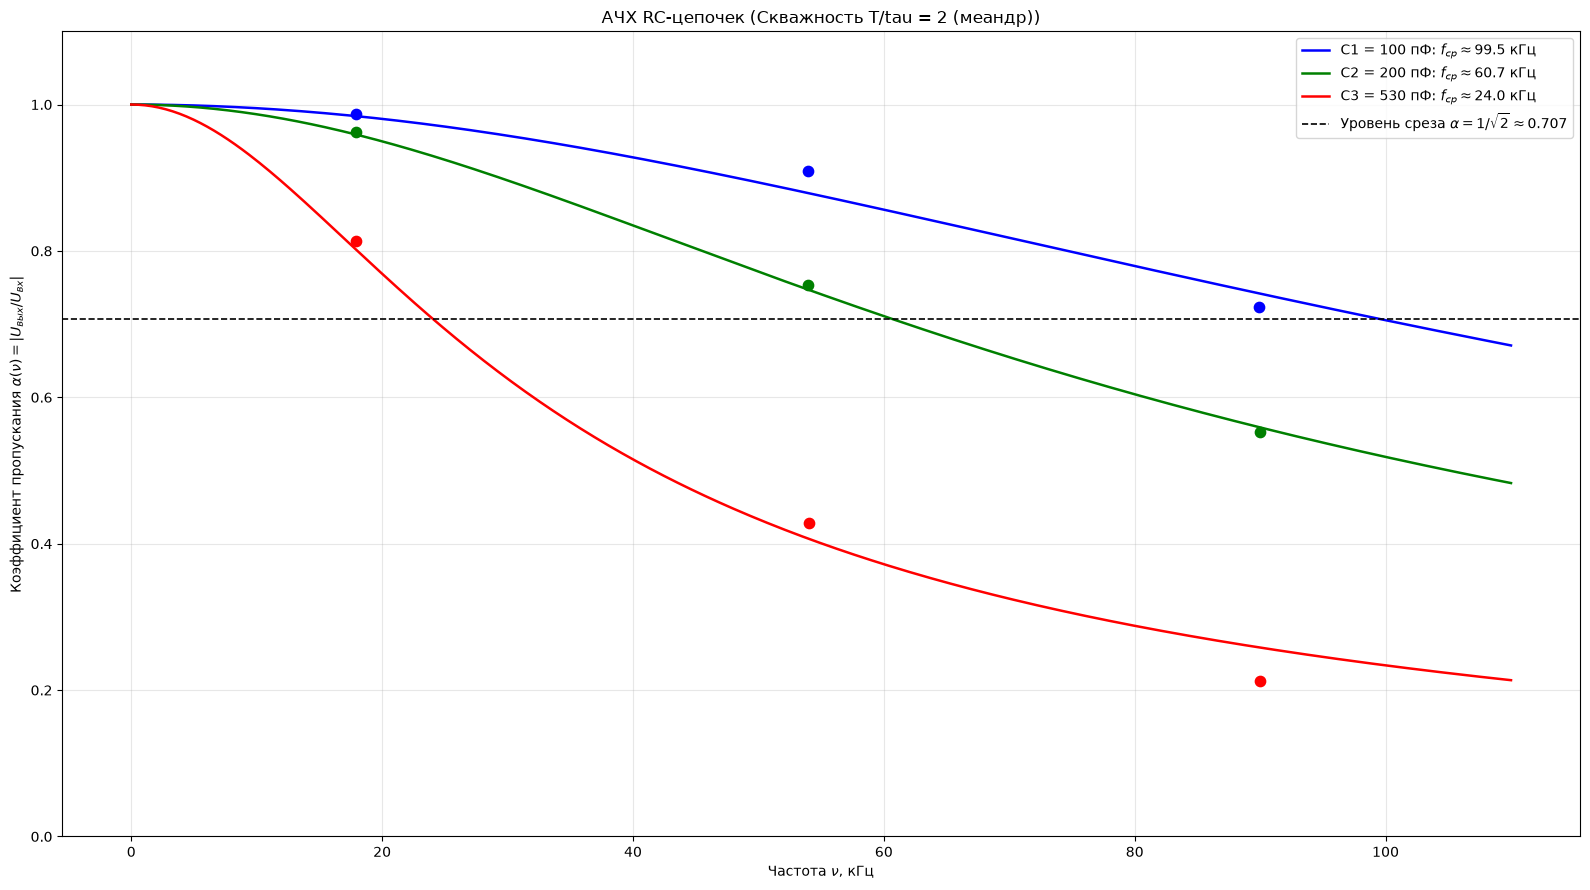


=== Скважность T/tau = 4 (duty = 0.25) ===
    Цепочка  f_ср эксп, кГц  f_ср теор, кГц
C1 = 100 пФ           101.0           159.2
C2 = 200 пФ            50.7            79.6
C3 = 530 пФ            24.9            30.0


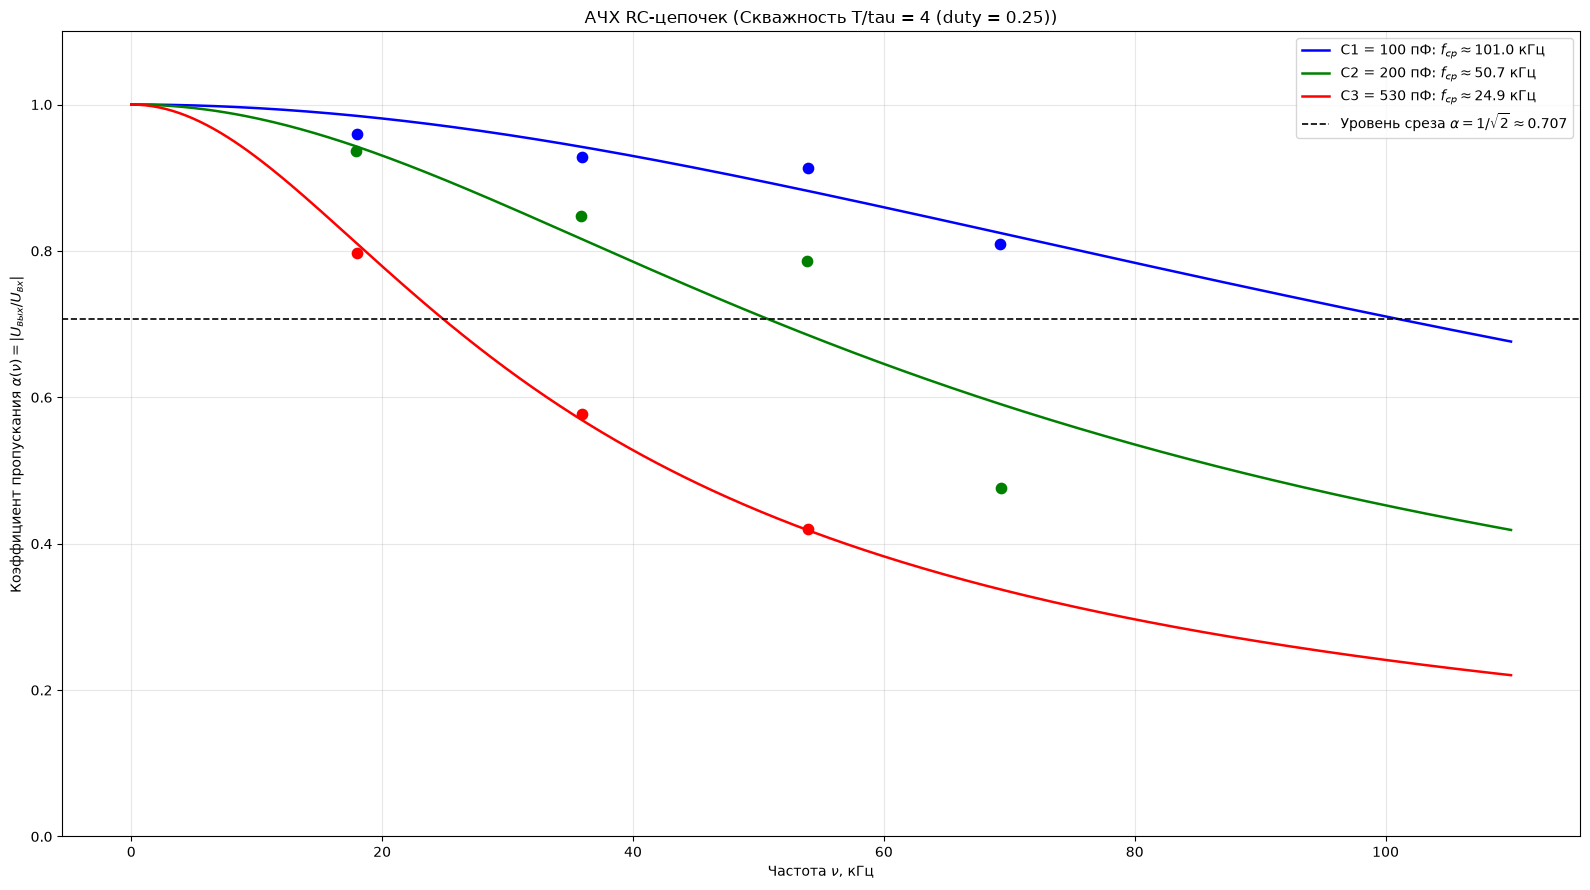

In [12]:
from dataclasses import dataclass
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

R_OHM = 10e3  # Сопротивление цепочки R = 10 кОм


@dataclass
class ExperimentWithC:
  C: float  # Ёмкость, Ф
  name: str  # Название цепочки для легенды
  harmonics: pd.DataFrame  # Выходной спектр
  A_in: np.ndarray  # Входные амплитуды из Задачи 2, мВ
  T: float  # Период, с

  def get_alpha(self) -> np.ndarray:
    """Коэффициент пропускания |U_вых / U_вх|."""
    return np.asarray(self.harmonics["A, mV"]) / self.A_in

  def theoretical_f_cut_khz(self) -> float:
    """Теоретическая частота среза f_ср = 1 / (2 * pi * R * C), кГц."""
    return (1.0 / (2.0 * np.pi * R_OHM * self.C)) / 1e3

A_IN_DUTY_2 = np.array((428.8, 137.0, 83.63))
A_IN_DUTY_4 = np.array((306.0, 197.5, 97.36, 37.37))

exp_duty2 = (
    ExperimentWithC(
        C=100e-12,
        name="C1 = 100 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (17.94, 53.99, 89.89),
            "A, mV": (423.5, 124.6, 60.5),
            "n": (1, 3, 5),
        }),
        A_in=A_IN_DUTY_2,
        T=(224.7 - 169.2) * 1e-6,
    ),
    ExperimentWithC(
        C=200e-12,
        name="C2 = 200 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (17.94, 53.92, 89.97),
            "A, mV": (412.8, 103.2, 46.26),
            "n": (1, 3, 5),
        }),
        A_in=A_IN_DUTY_2,
        T=(225.8 - 171.2) * 1e-6,
    ),
    ExperimentWithC(
        C=530e-12,
        name="C3 = 530 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (17.94, 54.06, 89.97),
            "A, mV": (348.8, 58.72, 17.79),
            "n": (1, 3, 5),
        }),
        A_in=A_IN_DUTY_2,
        T=(228.5 - 173.5) * 1e-6,
    ),
)

exp_duty4 = (
    ExperimentWithC(
        C=100e-12,
        name="C1 = 100 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (18.01, 35.93, 53.99, 69.22),
            "A, mV": (293.6, 183.3, 88.97, 30.25),
            "n": (1, 2, 3, 4),
        }),
        A_in=A_IN_DUTY_4,
        T=(225.0 - 169.6) * 1e-6,
    ),
    ExperimentWithC(
        C=200e-12,
        name="C2 = 200 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (17.94, 35.85, 53.84, 69.37),
            "A, mV": (286.5, 167.3, 76.51, 17.79),
            "n": (1, 2, 3, 4),
        }),
        A_in=A_IN_DUTY_4,
        T=(226.6 - 170.8) * 1e-6,
    ),
    ExperimentWithC(
        C=530e-12,
        name="C3 = 530 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (18.01, 35.93, 53.92),
            "A, mV": (243.8, 113.9, 40.93),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_4[:3],
        T=(230.4 - 173.8) * 1e-6,
    ),
)


def ach_curve(f: np.ndarray, f_cut: float) -> np.ndarray:
  return 1.0 / np.sqrt(1.0 + (f / f_cut) ** 2)


def analyze_block(experiments: tuple[ExperimentWithC, ...], title: str) -> None:
  f_grid = np.linspace(0, 110, 400)
  colors = ("b", "g", "r")
  summary = []

  plt.figure(figsize=(16,9))

  for exp, color in zip(experiments, colors):
    freq = np.asarray(exp.harmonics["freq, kHz"])
    alpha = exp.get_alpha()

    # Аппроксимация АЧХ для определения частоты среза
    popt, _ = curve_fit(ach_curve, freq, alpha, p0=(50.0,))
    f_cut_exp = float(popt.item(0))
    f_cut_theor = exp.theoretical_f_cut_khz()

    summary.append({
        "Цепочка": exp.name,
        "f_ср эксп, кГц": round(f_cut_exp, 1),
        "f_ср теор, кГц": round(f_cut_theor, 1),
    })

    plt.scatter(freq, alpha, color=color, s=55, zorder=3)
    plt.plot(
        f_grid,
        ach_curve(f_grid, f_cut_exp),
        color=color,
        linewidth=1.8,
        label=f"{exp.name}: $f_{{ср}} \\approx {f_cut_exp:.1f}$ кГц",
    )

  plt.axhline(
      1.0 / np.sqrt(2.0),
      color="k",
      linestyle="--",
      linewidth=1.2,
      label=r"Уровень среза $\alpha = 1/\sqrt{2} \approx 0.707$",
  )

  print(f"\n=== {title} ===")
  print(pd.DataFrame(summary).to_string(index=False))

  plt.title(f"АЧХ RC-цепочек ({title})")
  plt.xlabel("Частота $\\nu$, кГц")
  plt.ylabel(r"Коэффициент пропускания $\alpha(\nu) = |U_{вых}/U_{вх}|$")
  plt.ylim(0, 1.1)
  plt.grid(True, alpha=0.3)
  plt.legend()
  plt.tight_layout()
  plt.show()


analyze_block(exp_duty2, "Скважность T/tau = 2 (меандр)")
analyze_block(exp_duty4, "Скважность T/tau = 4 (duty = 0.25)")
